# 05 · Análisis y visualización

**Etapa 06 del pipeline** (*serving* y análisis). Lee el almacén `data/final/home_office.sqlite` con SQL y
responde las preguntas del proyecto: cuánto cuesta equipar un home office y qué conviene saber al comprar o al
compensar esos equipos.

| | Archivo |
| --- | --- |
| Entrada | `data/final/home_office.sqlite` (tablas `publicaciones`, `precios_por_gama`, `perfiles`, `ofertas_comunes`, `excluidos`) |
| Salida | `docs/parte_2/figuras/f05_*.png`, `data/final/metricas.json` (sección `insights`) |

**Técnicas del curso**: agregación con `groupby` y `pivot_table` y unión de tablas (U3_L8), consultas SQL
sobre el almacén (etapa *serving* del ciclo de vida, U5_T1), visualización con matplotlib y seaborn. Las
pruebas de Mann-Whitney y de Spearman (scipy) se usan para comprobar si una diferencia entre grupos es
sistemática y no casual: los precios no siguen una distribución normal, por eso se eligen pruebas basadas en
rangos.

Cada gráfico responde una pregunta y lleva su lectura debajo. `precio_relativo` (notebook 04) es la puntuación Z
del log-precio dentro de cada componente: permite comparar productos de componentes distintos.

In [1]:
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML
from scipy.stats import mannwhitneyu, spearmanr

import comun
from comun import FINAL, guardar_figura, leer_metricas, registrar, soles

comun.aplicar_estilo()
conexion = sqlite3.connect(FINAL / 'home_office.sqlite')
consulta = lambda sql: pd.read_sql(sql, conexion)
pub = consulta('SELECT * FROM publicaciones')
pub['gama'] = pd.Categorical(pub['gama'], comun.ORDEN_GAMAS, ordered=True)
gamas = consulta('SELECT * FROM precios_por_gama')
perfiles = consulta('SELECT * FROM perfiles')
O = comun.ORDEN_COMPONENTES
nombre = lambda c: 'audífonos' if c == 'audifonos' else c
ETQ = [nombre(c) for c in O]
lista = lambda cs: ', '.join(map(nombre, cs[:-1])) + (' y ' if len(cs) > 1 else '') + nombre(cs[-1]) if cs else ''
print('publicaciones:', pub.shape, '| tablas:', consulta("SELECT name FROM sqlite_master WHERE type='table'")['name'].tolist())

publicaciones: (2714, 41) | tablas: ['publicaciones', 'precios_por_gama', 'perfiles', 'ofertas_comunes', 'excluidos']


## 1. ¿Cuánto cuesta equipar un home office?

### 1.1 Por perfil de equipamiento

El perfil reúne un componente de cada tipo en la misma gama (notebook 04). La barra horizontal es el rango que
suma la mitad central de la oferta de cada componente; el punto, la suma de medianas.

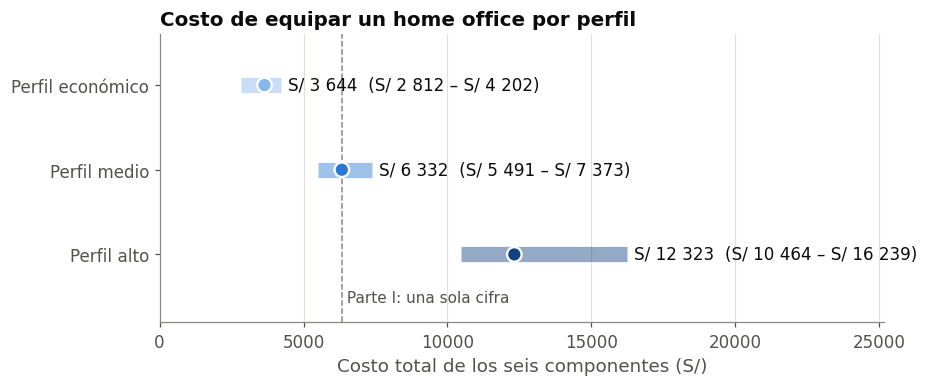

Lectura: Un home office cuesta S/ 3 644 en gama económica, S/ 6 332 en gama media y S/ 12 323 en gama alta: el perfil alto cuesta 3.4 veces el económico. La cifra única de la Parte I (S/ 6 335) coincide con el perfil medio, pero oculta que el presupuesto real depende del nivel de equipamiento elegido.


In [2]:
perfiles = perfiles.set_index('perfil').loc[['económico', 'medio', 'alto']]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
y = np.arange(len(perfiles))
colores = [comun.COLOR_GAMA[g] for g in comun.ORDEN_GAMAS]
ax.hlines(y, perfiles['costo_q1'], perfiles['costo_q3'], color=colores, linewidth=10, alpha=0.45)
ax.scatter(perfiles['costo_mediano'], y, color=colores, s=90, zorder=3, edgecolor='white', linewidth=1.5)
for yi, (perfil, fila) in zip(y, perfiles.iterrows()):
    ax.text(fila['costo_q3'] + 250, yi, f'{soles(fila["costo_mediano"])}  ({soles(fila["costo_q1"])} – {soles(fila["costo_q3"])})',
            va='center', color=comun.TINTA, fontsize=11)
parte1 = leer_metricas()['costos']['suma_medianas_parte1']
ax.axvline(parte1, color=comun.TINTA_TENUE, linestyle='--', linewidth=1)
ax.text(parte1, len(perfiles) - 0.4, ' Parte I: una sola cifra', color=comun.TINTA_SECUNDARIA, fontsize=10, va='bottom')
ax.set_yticks(y, [f'Perfil {p}' for p in perfiles.index])
ax.set(title='Costo de equipar un home office por perfil', xlabel='Costo total de los seis componentes (S/)',
       xlim=(0, perfiles['costo_q3'].max() * 1.55), ylim=(-0.6, len(perfiles) - 0.2))
ax.grid(axis='y', visible=False)
ax.invert_yaxis()
eco, med, alt = perfiles['costo_mediano']
guardar_figura(fig, 'f05_costo_perfiles',
               '¿Cuánto cuesta equipar un home office según el nivel de equipamiento?',
               f'Un home office cuesta {soles(eco)} en gama económica, {soles(med)} en gama media y {soles(alt)} en gama '
               f'alta: el perfil alto cuesta {alt / eco:.1f} veces el económico. La cifra única de la Parte I '
               f'({soles(parte1)}) coincide con el perfil medio, pero oculta que el presupuesto real depende del nivel de '
               f'equipamiento elegido.')

### 1.2 ¿Qué componente pesa más en cada perfil?

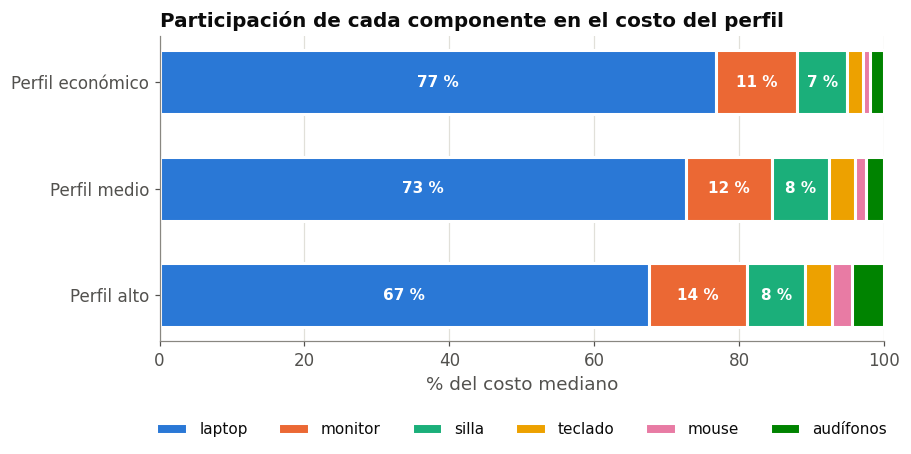

Lectura: La laptop concentra entre 67 % y 77 % del costo según el perfil. Monitor y silla suman entre 18 % y 22 %; teclado, mouse y audífonos juntos no llegan a 11 %. Elegir la gama de la laptop es la decisión que más mueve el presupuesto.


In [3]:
composicion = perfiles[[f'mediana_{c}' for c in O]].div(perfiles['costo_mediano'], axis=0) * 100
composicion.columns = O
fig, ax = plt.subplots(figsize=(8.5, 3.6))
izquierda = np.zeros(len(composicion))
for c in O:
    ax.barh(y, composicion[c], left=izquierda, color=comun.COLOR_COMPONENTE[c], label=nombre(c), height=0.6,
            edgecolor='white', linewidth=2)
    for yi, (valor, base) in enumerate(zip(composicion[c], izquierda)):
        if valor >= 6:
            ax.text(base + valor / 2, yi, f'{valor:.0f} %', ha='center', va='center', color='white', fontsize=10,
                    fontweight='bold')
    izquierda += composicion[c].to_numpy()
ax.set_yticks(y, [f'Perfil {p}' for p in composicion.index])
ax.set(title='Participación de cada componente en el costo del perfil', xlabel='% del costo mediano', xlim=(0, 100))
ax.legend(ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.22), fontsize=10)
ax.grid(axis='y', visible=False)
ax.invert_yaxis()
guardar_figura(fig, 'f05_composicion_perfiles',
               '¿En qué componente se concentra el presupuesto?',
               f'La laptop concentra entre {composicion["laptop"].min():.0f} % y {composicion["laptop"].max():.0f} % del '
               f'costo según el perfil. Monitor y silla suman entre {(composicion["monitor"] + composicion["silla"]).min():.0f} % '
               f'y {(composicion["monitor"] + composicion["silla"]).max():.0f} %; teclado, mouse y audífonos juntos no '
               f'llegan a {(composicion[["teclado", "mouse", "audifonos"]].sum(axis=1)).max():.0f} %. Elegir la gama de la '
               f'laptop es la decisión que más mueve el presupuesto.')

### 1.3 Por componente y gama (FR-020)

Valor central (mediana) y rango (cuartiles 1 y 3) de cada componente en cada gama, leídos del almacén.

In [4]:
tabla_gamas = consulta('''
    SELECT componente, gama, n, q1, mediana, q3
    FROM precios_por_gama
''').pivot_table(index='componente', columns='gama', values='mediana').reindex(index=O, columns=comun.ORDEN_GAMAS)
HTML(tabla_gamas.style.set_uuid('precio_por_gama').format(lambda v: soles(v)).to_html())

gama,económica,media,alta
componente,,,
laptop,S/ 2 800,S/ 4 599,S/ 8 315
monitor,S/ 408,S/ 750,S/ 1 679
silla,S/ 251,S/ 500,S/ 980
teclado,S/ 76,S/ 229,S/ 459
mouse,S/ 40,S/ 98,S/ 344
audifonos,S/ 69,S/ 155,S/ 546


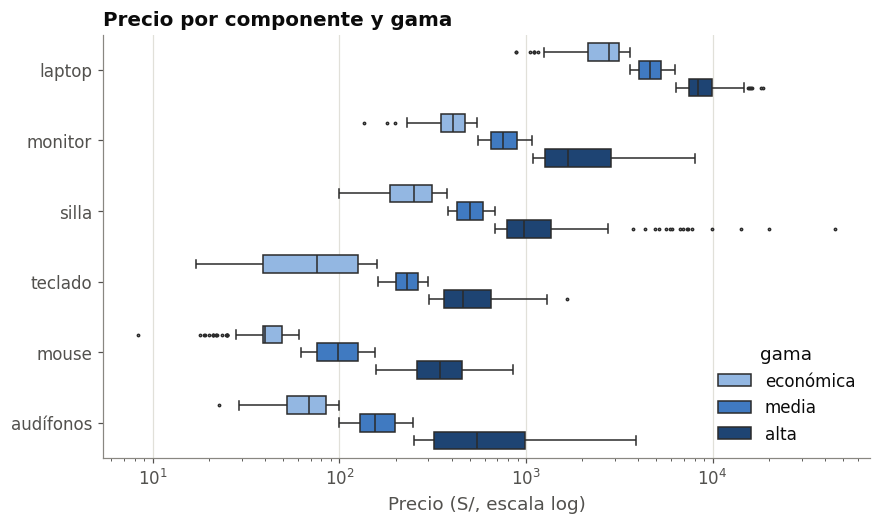

Lectura: Las gamas no se superponen por construcción, pero la distancia entre ellas varía mucho: la laptop de gama alta cuesta 3.0 veces la económica, y el mayor salto relativo está en mouse (8.6 veces). La mediana de cada gama es la referencia que se suma en los perfiles.


In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=pub, y='componente', x='precio', hue='gama', order=O, hue_order=comun.ORDEN_GAMAS,
            palette=comun.COLOR_GAMA, log_scale=True, fliersize=1.5, width=0.75, ax=ax)
ax.set(title='Precio por componente y gama', xlabel='Precio (S/, escala log)', ylabel='')
ax.set_yticks(range(len(O)), ETQ)
ax.legend(title='gama', loc='lower right')
salto_laptop = tabla_gamas.loc['laptop', 'alta'] / tabla_gamas.loc['laptop', 'económica']
salto_max = (tabla_gamas['alta'] / tabla_gamas['económica']).idxmax()
guardar_figura(fig, 'f05_precio_por_gama',
               '¿Cuánto se separan los precios entre gamas dentro de cada componente?',
               f'Las gamas no se superponen por construcción, pero la distancia entre ellas varía mucho: la laptop de gama '
               f'alta cuesta {salto_laptop:.1f} veces la económica, y el mayor salto relativo está en {nombre(salto_max)} '
               f'({tabla_gamas.loc[salto_max, "alta"] / tabla_gamas.loc[salto_max, "económica"]:.1f} veces). La mediana de '
               f'cada gama es la referencia que se suma en los perfiles.')

## 2. Promociones: ¿un descuento significa un buen precio?

In [6]:
promo = consulta('''
    SELECT componente,
           AVG(tiene_descuento) * 100 AS pct_con_descuento,
           SUM(descuento_inflado) AS descuento_inflado
    FROM publicaciones GROUP BY componente
''').set_index('componente').reindex(O)
promo['descuento_mediano'] = pub[pub['tiene_descuento'] == 1].groupby('componente')['descuento_pct'].median()
con, sin = (pub.loc[pub['tiene_descuento'] == 1, 'precio_relativo'], pub.loc[pub['tiene_descuento'] == 0, 'precio_relativo'])
prueba_promo = mannwhitneyu(con, sin)
promo['precio_relativo_con'] = pub[pub['tiene_descuento'] == 1].groupby('componente')['precio_relativo'].median()
promo['precio_relativo_sin'] = pub[pub['tiene_descuento'] == 0].groupby('componente')['precio_relativo'].median()
promo.round(2)

,pct_con_descuento,descuento_inflado,descuento_mediano,precio_relativo_con,precio_relativo_sin
componente,,,,,
laptop,65.26,4,22.78,-0.00,-0.18
monitor,62.11,0,30.02,-0.05,-0.23
silla,63.40,0,45.12,-0.15,0.13
teclado,46.76,2,29.29,0.17,0.17
mouse,41.26,1,24.67,0.05,-0.22
audifonos,54.99,0,32.01,0.04,-0.33


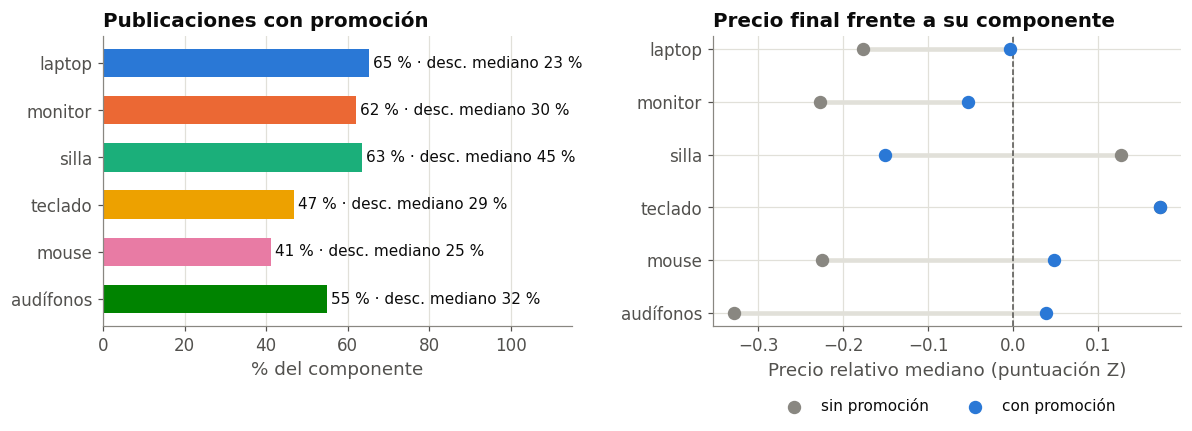

Lectura: No. Entre 41 % y 65 % de las publicaciones anuncian una promoción, con descuentos medianos de hasta 45 % (sillas). Pero en 4 de 6 componentes el precio final de las ofertas con descuento es mayor que el de las que no tienen promoción (Mann-Whitney, p = 0.0008). El porcentaje de descuento no indica un buen precio: hay que comparar el precio final.


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.barh(ETQ, promo['pct_con_descuento'], color=[comun.COLOR_COMPONENTE[c] for c in O], height=0.6)
for yi, (pct, d) in enumerate(zip(promo['pct_con_descuento'], promo['descuento_mediano'])):
    ax1.text(pct + 1, yi, f'{pct:.0f} % · desc. mediano {d:.0f} %', va='center', fontsize=10, color=comun.TINTA)
ax1.set(title='Publicaciones con promoción', xlabel='% del componente', xlim=(0, 115))
ax1.invert_yaxis()
ax1.grid(axis='y', visible=False)
for yi, c in enumerate(O):
    ax2.plot([promo.loc[c, 'precio_relativo_sin'], promo.loc[c, 'precio_relativo_con']], [yi, yi],
             color=comun.REJILLA, linewidth=3, zorder=1)
ax2.scatter(promo['precio_relativo_sin'], range(len(O)), color=comun.TINTA_TENUE, s=60, label='sin promoción', zorder=2)
ax2.scatter(promo['precio_relativo_con'], range(len(O)), color='#2a78d6', s=60, label='con promoción', zorder=3)
ax2.axvline(0, color=comun.TINTA_SECUNDARIA, linewidth=1, linestyle='--')
ax2.set_yticks(range(len(O)), ETQ)
ax2.set(title='Precio final frente a su componente', xlabel='Precio relativo mediano (puntuación Z)')
ax2.invert_yaxis()
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=10)
fig.tight_layout()
mas_caras = int((promo['precio_relativo_con'] > promo['precio_relativo_sin']).sum())
guardar_figura(fig, 'f05_promociones',
               '¿Las publicaciones con descuento son más baratas?',
               f'No. Entre {promo["pct_con_descuento"].min():.0f} % y {promo["pct_con_descuento"].max():.0f} % de las '
               f'publicaciones anuncian una promoción, con descuentos medianos de hasta {promo["descuento_mediano"].max():.0f} % '
               f'(sillas). Pero en {mas_caras} de 6 componentes el precio final de las ofertas con descuento es mayor '
               f'que el de las que no tienen promoción (Mann-Whitney, p = {prueba_promo.pvalue:.4f}). El porcentaje de '
               f'descuento no indica un buen precio: hay que comparar el precio final.')

## 3. Financiamiento en cuotas

In [8]:
cuotas = consulta('''
    SELECT numero_cuotas, COUNT(*) AS publicaciones FROM publicaciones
    WHERE ofrece_cuotas = 1 GROUP BY numero_cuotas ORDER BY numero_cuotas
''')
pct_cuotas = pub['ofrece_cuotas'].mean() * 100
cuota_mensual = pd.DataFrame({f'{n} cuotas': perfiles['costo_mediano'] / n for n in (6, 12)}).round(0)
display(cuotas)
cuota_mensual

,numero_cuotas,publicaciones
0,6.0,2118
1,12.0,524
2,18.0,15


,6 cuotas,12 cuotas
perfil,,
económico,607.0,304.0
medio,1055.0,528.0
alto,2054.0,1027.0


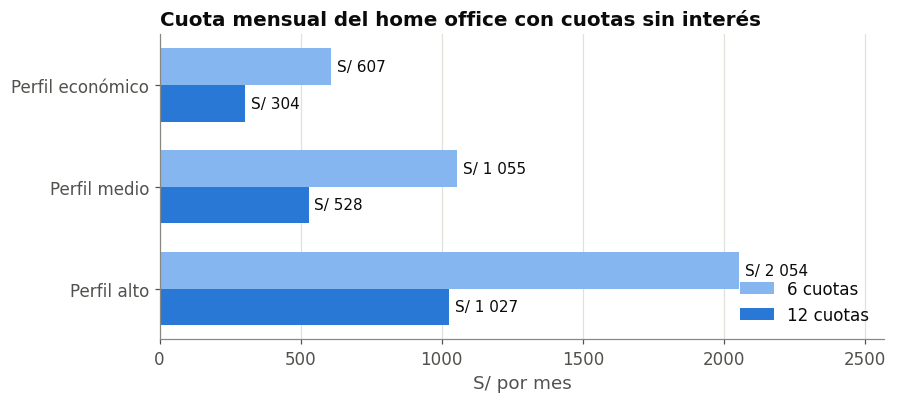

Lectura: El 97.9 % de las publicaciones ofrece cuotas, todas sin interés y sobre todo en 6 (80 %) o 12 cuotas. Un perfil medio cuesta S/ 528 al mes en 12 cuotas sin recargo: financiar no encarece el equipo, solo reparte el gasto.


In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ancho = 0.36
for i, (columna, color) in enumerate(zip(cuota_mensual.columns, ['#86b6ef', '#2a78d6'])):
    barras = ax.barh(y + (i - 0.5) * ancho, cuota_mensual[columna], height=ancho, color=color, label=columna)
    for barra, valor in zip(barras, cuota_mensual[columna]):
        ax.text(valor + 20, barra.get_y() + barra.get_height() / 2, soles(valor), va='center', fontsize=10)
ax.set_yticks(y, [f'Perfil {p}' for p in cuota_mensual.index])
ax.set(title='Cuota mensual del home office con cuotas sin interés', xlabel='S/ por mes',
       xlim=(0, cuota_mensual.max().max() * 1.25))
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
ax.invert_yaxis()
guardar_figura(fig, 'f05_cuotas',
               '¿Cuánto se paga al mes si se financia el home office?',
               f'El {pct_cuotas:.1f} % de las publicaciones ofrece cuotas, todas sin interés y sobre todo en 6 '
               f'({cuotas.set_index("numero_cuotas").loc[6, "publicaciones"] / cuotas["publicaciones"].sum() * 100:.0f} %) o '
               f'12 cuotas. Un perfil medio cuesta {soles(cuota_mensual.loc["medio", "12 cuotas"])} al mes en 12 cuotas '
               f'sin recargo: financiar no encarece el equipo, solo reparte el gasto.')

## 4. Reputación y popularidad

In [10]:
con_vendidos = pub.dropna(subset=['vendidos_min'])
con_calificacion = pub.dropna(subset=['calificacion'])
rho_vendidos = spearmanr(con_vendidos['vendidos_min'], con_vendidos['precio_relativo'])
rho_calificacion = spearmanr(con_calificacion['calificacion'], con_calificacion['precio_relativo'])
popularidad = con_vendidos.assign(tramo=pd.cut(con_vendidos['vendidos_min'], [0, 25, 50, 100, 500, np.inf],
                                               labels=['+25', '+50', '+100', '+500', '+1000 o más'])) \
    .groupby('tramo', observed=True)['precio_relativo'].agg(['size', 'median'])
popularidad

,size,median
tramo,,
+25,267,-0.15540
+50,249,-0.06610
+100,350,-0.32980
+500,76,-0.31445
+1000 o más,58,-0.48915


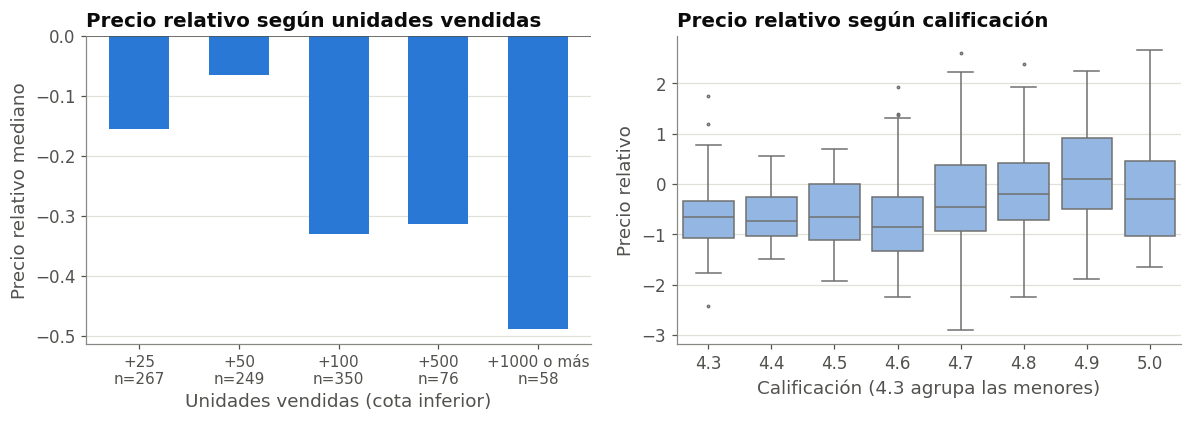

Lectura: Van en sentidos opuestos. La relación entre ventas y precio es débil en general (Spearman ρ = -0.08, p = 0.014), pero marcada en el extremo: las publicaciones con +1000 vendidos tienen un precio relativo mediano de -0.49, más baratas que su componente. En cambio, las mejor calificadas son más caras (ρ = 0.24, p < 0,001). Lo más vendido no es lo mejor valorado. Recordatorio: solo 36 % de las publicaciones muestra reseñas, y faltan más en los productos caros (notebook 02).


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
etiquetas_tramo = [f'{t}\nn={n}' for t, n in zip(popularidad.index.astype(str), popularidad['size'])]
ax1.bar(etiquetas_tramo, popularidad['median'], color='#2a78d6', width=0.6)
ax1.axhline(0, color=comun.TINTA_SECUNDARIA, linewidth=1)
ax1.set(title='Precio relativo según unidades vendidas', xlabel='Unidades vendidas (cota inferior)',
        ylabel='Precio relativo mediano')
ax1.tick_params(axis='x', labelsize=10)
ax1.grid(axis='x', visible=False)
sns.boxplot(data=con_calificacion.assign(calif=con_calificacion['calificacion'].clip(lower=4.3).round(1)),
            x='calif', y='precio_relativo', color='#86b6ef', fliersize=1.5, ax=ax2)
ax2.set(title='Precio relativo según calificación', xlabel='Calificación (4.3 agrupa las menores)',
        ylabel='Precio relativo')
fig.tight_layout()
guardar_figura(fig, 'f05_reputacion',
               '¿Cómo se relacionan popularidad, calificación y precio?',
               f'Van en sentidos opuestos. La relación entre ventas y precio es débil en general (Spearman '
               f'ρ = {rho_vendidos.statistic:.2f}, p = {rho_vendidos.pvalue:.3f}), pero marcada en el extremo: las '
               f'publicaciones con +1000 vendidos tienen un precio relativo mediano de {popularidad["median"].iloc[-1]:.2f}, '
               f'más baratas que su componente. En cambio, las mejor calificadas son más caras '
               f'(ρ = {rho_calificacion.statistic:.2f}, p < 0,001). Lo más vendido no es lo mejor valorado. '
               f'Recordatorio: solo {len(con_calificacion) / len(pub) * 100:.0f} % de las publicaciones muestra reseñas, '
               f'y faltan más en los productos caros (notebook 02).')

## 5. Marca, tipo de vendedor y anuncios

In [12]:
def comparar(columna):
    a = pub.loc[pub[columna] == 1, 'precio_relativo']
    b = pub.loc[pub[columna] == 0, 'precio_relativo']
    return pd.Series({'publicaciones': len(a), 'mediana sí': a.median(), 'mediana no': b.median(),
                      'diferencia': a.median() - b.median(), 'p (Mann-Whitney)': mannwhitneyu(a, b).pvalue})


grupos_vendedor = pd.DataFrame({'anuncio patrocinado': comparar('es_publicidad'),
                                'tienda de la marca': comparar('tienda_de_marca'),
                                'vendedor visible': comparar('vendedor_visible'),
                                'envío gratis': comparar('envio_gratis')}).T
grupos_vendedor.round(4)

,publicaciones,mediana sí,mediana no,diferencia,p (Mann-Whitney)
anuncio patrocinado,91.0,-0.4928,-0.0419,-0.4509,0.0000
tienda de la marca,352.0,0.1160,-0.0784,0.1944,0.0000
vendedor visible,1185.0,0.1102,-0.1896,0.2998,0.0000
envío gratis,2503.0,-0.0408,-0.3339,0.2931,0.0004


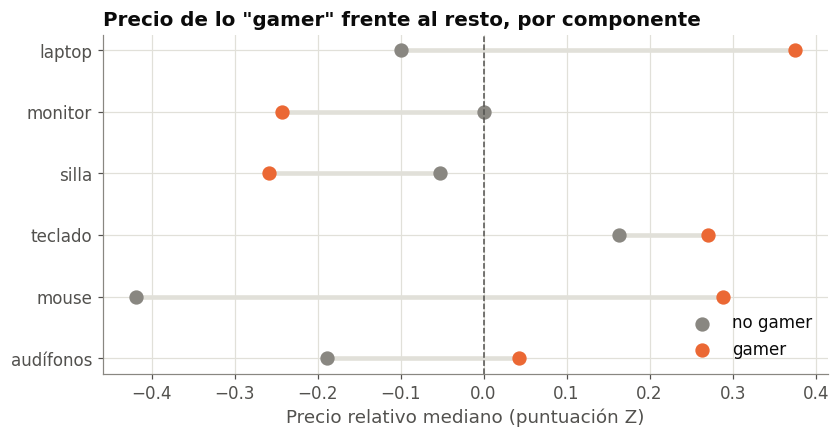

Lectura: Depende del componente. "Gamer" encarece laptop, teclado, mouse y audífonos (el mouse gamer está 0.71 desviaciones por encima del resto), pero no monitor ni silla: ahí los productos gamer son incluso más baratos que el resto. Para un home office, un mouse o una laptop gamer agregan costo por prestaciones que el trabajo de oficina no necesita.


In [13]:
gamer = pub.groupby(['componente', 'es_gamer'])['precio_relativo'].median().unstack().reindex(O)
gamer.columns = ['no gamer', 'gamer']
fig, ax = plt.subplots(figsize=(8.5, 4))
for yi, c in enumerate(O):
    ax.plot([gamer.loc[c, 'no gamer'], gamer.loc[c, 'gamer']], [yi, yi], color=comun.REJILLA, linewidth=3, zorder=1)
ax.scatter(gamer['no gamer'], range(len(O)), color=comun.TINTA_TENUE, s=70, label='no gamer', zorder=2)
ax.scatter(gamer['gamer'], range(len(O)), color='#eb6834', s=70, label='gamer', zorder=3)
ax.axvline(0, color=comun.TINTA_SECUNDARIA, linewidth=1, linestyle='--')
ax.set_yticks(range(len(O)), ETQ)
ax.set(title='Precio de lo "gamer" frente al resto, por componente', xlabel='Precio relativo mediano (puntuación Z)')
ax.legend(loc='lower right')
ax.invert_yaxis()
diferencia_gamer = (gamer['gamer'] - gamer['no gamer']).round(2)
encarece = diferencia_gamer[diferencia_gamer > 0.1].index.tolist()
abarata = diferencia_gamer[diferencia_gamer < -0.1].index.tolist()
guardar_figura(fig, 'f05_gamer',
               '¿Cuesta más un equipo con la etiqueta "gamer"?',
               f'Depende del componente. "Gamer" encarece {lista(encarece)} (el mouse gamer está '
               f'{diferencia_gamer["mouse"]:.2f} desviaciones por encima del resto), pero no {lista(abarata).replace(" y ", " ni ")}: ahí los '
               f'productos gamer son incluso más baratos que el resto. Para un home office, un mouse o una laptop gamer '
               f'agregan costo por prestaciones que el trabajo de oficina no necesita.')

## 6. Especificaciones: laptops

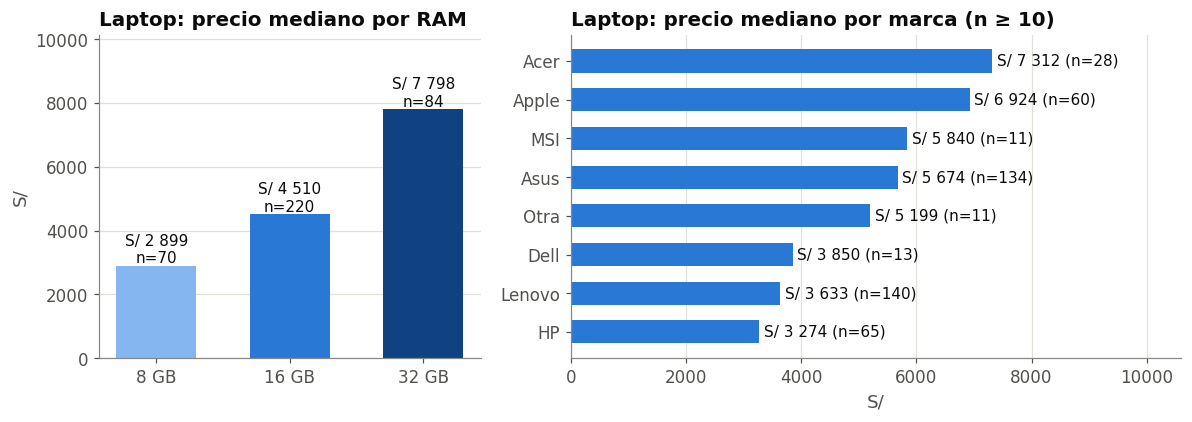

Lectura: La memoria marca escalones claros: la mediana pasa de S/ 2 899 con 8 GB a S/ 4 510 con 16 GB y S/ 7 798 con 32 GB. Entre marcas, la mediana va de S/ 3 274 (HP) a S/ 7 312 (Acer). Para trabajo de oficina, 16 GB es la configuración más ofrecida (220 laptops) y queda en la gama media.


In [14]:
laptops = pub[pub['componente'] == 'laptop']
por_ram = laptops[laptops['ram_gb'].isin([8, 16, 32])].groupby('ram_gb')['precio'].agg(['size', 'median'])
por_marca = laptops.groupby('marca')['precio'].agg(['size', 'median']).query('size >= 10').sort_values('median')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [1, 1.6]})
ax1.bar([f'{int(r)} GB' for r in por_ram.index], por_ram['median'], color=['#86b6ef', '#2a78d6', '#104281'], width=0.6)
for x, (n, m) in enumerate(zip(por_ram['size'], por_ram['median'])):
    ax1.text(x, m, f'{soles(m)}\nn={n}', ha='center', va='bottom', fontsize=10)
ax1.set(title='Laptop: precio mediano por RAM', ylabel='S/', ylim=(0, por_ram['median'].max() * 1.3))
ax1.grid(axis='x', visible=False)
grafia = lambda m: m.upper() if m in ('hp', 'msi') else m.capitalize()
ax2.barh([grafia(m) for m in por_marca.index], por_marca['median'], color=comun.COLOR_COMPONENTE['laptop'], height=0.6)
for yi, (n, m) in enumerate(zip(por_marca['size'], por_marca['median'])):
    ax2.text(m + 80, yi, f'{soles(m)} (n={n})', va='center', fontsize=10)
ax2.set(title='Laptop: precio mediano por marca (n ≥ 10)', xlabel='S/', xlim=(0, por_marca['median'].max() * 1.45))
ax2.grid(axis='y', visible=False)
fig.tight_layout()
guardar_figura(fig, 'f05_laptops',
               '¿Qué explica el precio de una laptop?',
               f'La memoria marca escalones claros: la mediana pasa de {soles(por_ram.loc[8, "median"])} con 8 GB a '
               f'{soles(por_ram.loc[16, "median"])} con 16 GB y {soles(por_ram.loc[32, "median"])} con 32 GB. Entre marcas, la '
               f'mediana va de {soles(por_marca["median"].iloc[0])} ({grafia(por_marca.index[0])}) a {soles(por_marca["median"].iloc[-1])} '
               f'({grafia(por_marca.index[-1])}). Para trabajo de oficina, 16 GB es la configuración más ofrecida '
               f'({int(laptops["ram_gb"].eq(16).sum())} laptops) y queda en la gama media.')

## 7. Kits de teclado y mouse frente a comprarlos por separado

El notebook 01 apartó los kits de teclado y mouse del costo por componente. Aquí se comparan con la suma de un
teclado y un mouse de gama económica, que es la gama con la que compiten.

In [15]:
kits = consulta('''
    SELECT precio FROM excluidos
    WHERE archivo = '01_ajenas_al_componente.csv' AND detalle = 'combo de varios componentes'
      AND titulo LIKE '%teclado%' AND (titulo LIKE '%mouse%' OR titulo LIKE '%ratón%' OR titulo LIKE '%raton%')
''')
kits['precio'] = pd.to_numeric(kits['precio'])
por_separado = tabla_gamas.loc['teclado', 'económica'] + tabla_gamas.loc['mouse', 'económica']
kit_mediano = kits['precio'].median()
ahorro_kit = (1 - kit_mediano / por_separado) * 100
print(f'Kits teclado + mouse: {len(kits)} | mediana {soles(kit_mediano, 2)} | teclado + mouse económicos por separado: '
      f'{soles(por_separado, 2)} | ahorro {ahorro_kit:.0f} %')

Kits teclado + mouse: 133 | mediana S/ 119,60 | teclado + mouse económicos por separado: S/ 115,85 | ahorro -3 %


## 8. Anomalías y estabilidad de precios

- **Atípicos conservados** (notebook 02): extremos plausibles, sobre todo sillas premium, audífonos de alta
  gama y minitecladas baratas. No se eliminaron; el análisis usa medianas y escala logarítmica.
- **Estabilidad** (notebook 03): la mayoría de las ofertas presentes en ambas capturas no cambió de precio en dos
  días.

In [16]:
metricas = leer_metricas()
anomalias = pd.Series({
    'atípicos de precio conservados': int(pub['atipico_precio'].sum()),
    'excluidos por error comprobable': metricas['atipicos']['excluidos_por_error'],
    'ofertas en ambas capturas': metricas['integracion']['comunes_por_oferta'],
    '% sin cambio de precio en dos días': round(metricas['integracion']['sin_cambio_pct'], 1),
    'promociones con descuento inflado': int(pub['descuento_inflado'].sum()),
})
anomalias.to_frame('valor')

,valor
atípicos de precio conservados,35.0
excluidos por error comprobable,1.0
ofertas en ambas capturas,767.0
% sin cambio de precio en dos días,74.7
promociones con descuento inflado,7.0


## 9. Insights para los usuarios (FR-023)

Cada insight indica a quién sirve, qué acción recomienda y la cifra que lo respalda.

In [17]:
silla_envio = pub[pub['componente'] == 'silla']['envio_gratis'].mean() * 100
anuncio = grupos_vendedor.loc['anuncio patrocinado']
insights = [
    {'usuario': 'Área de RR. HH. o empleador',
     'hallazgo': f'El valor de mercado de un home office completo depende del nivel de equipamiento: {soles(eco)} '
                 f'(económico), {soles(med)} (medio) y {soles(alt)} (alto).',
     'accion': 'Fijar la provisión o la compensación de la Ley 31572 por perfil y no con una cifra única, y declarar '
               'la fecha de los precios usados.',
     'cifra': f'perfil medio {soles(med)}; rango {soles(perfiles.loc["medio", "costo_q1"])} – '
              f'{soles(perfiles.loc["medio", "costo_q3"])}'},
    {'usuario': 'Trabajador o estudiante',
     'hallazgo': f'La laptop concentra entre {composicion["laptop"].min():.0f} % y {composicion["laptop"].max():.0f} % '
                 f'del costo; los periféricos juntos, menos de {(composicion[["teclado", "mouse", "audifonos"]].sum(axis=1)).max():.0f} %.',
     'accion': 'Definir primero la gama de la laptop (16 GB de RAM basta para oficina) y no buscar ahorro en los '
               'periféricos.',
     'cifra': f'laptop de 16 GB: {soles(por_ram.loc[16, "median"])} frente a {soles(por_ram.loc[32, "median"])} con 32 GB'},
    {'usuario': 'Trabajador o estudiante',
     'hallazgo': 'Un descuento anunciado no garantiza un buen precio: las ofertas con promoción no son más baratas que '
                 'las demás de su componente.',
     'accion': 'Comparar el precio final entre publicaciones del mismo componente y gama, no el porcentaje de descuento.',
     'cifra': f'{mas_caras} de 6 componentes con precio relativo mayor con promoción; p = {prueba_promo.pvalue:.4f}'},
    {'usuario': 'Trabajador o estudiante',
     'hallazgo': f'El {pct_cuotas:.0f} % de las ofertas tiene cuotas sin interés.',
     'accion': 'Financiar en 12 cuotas sin interés para repartir el gasto sin pagar más.',
     'cifra': f'perfil medio: {soles(cuota_mensual.loc["medio", "12 cuotas"])} al mes'},
    {'usuario': 'Trabajador o estudiante con presupuesto ajustado',
     'hallazgo': (f'Un kit de teclado y mouse cuesta {abs(ahorro_kit):.0f} % menos que comprarlos por separado en gama '
                  f'económica.' if ahorro_kit > 2 else
                  f'Un kit de teclado y mouse no ahorra: cuesta {abs(ahorro_kit):.0f} % más que comprar un teclado y un '
                  f'mouse económicos por separado.' if ahorro_kit < -2 else
                  'Un kit de teclado y mouse cuesta prácticamente lo mismo que comprarlos por separado en gama económica.'),
     'accion': ('En el perfil económico, comprar teclado y mouse en kit.' if ahorro_kit > 2 else
                'En el perfil económico, elegir teclado y mouse por separado: por el mismo dinero se escoge cada uno.'),
     'cifra': f'kit mediano {soles(kit_mediano, 2)} frente a {soles(por_separado, 2)} por separado'},
    {'usuario': 'Trabajador o estudiante',
     'hallazgo': f'La etiqueta "gamer" encarece {lista(encarece)}.',
     'accion': 'Para trabajo de oficina, evitar mouse y laptops gamer: pagan prestaciones que no se usan.',
     'cifra': f'mouse gamer: +{diferencia_gamer["mouse"]:.2f} desviaciones sobre el resto'},
    {'usuario': 'Trabajador o estudiante',
     'hallazgo': f'Los anuncios patrocinados no son más caros: su precio relativo mediano es {anuncio["mediana sí"]:.2f} '
                 f'frente a {anuncio["mediana no"]:.2f} de los resultados orgánicos.',
     'accion': 'No descartar los anuncios al comparar: suelen estar entre las opciones más baratas de su componente.',
     'cifra': f'p = {anuncio["p (Mann-Whitney)"]:.1e}'},
    {'usuario': 'Trabajador que compra una silla',
     'hallazgo': f'La silla es el componente con menos envío gratuito ({silla_envio:.0f} % frente a más de 90 % en los demás).',
     'accion': 'Sumar el costo de envío al comparar sillas.',
     'cifra': f'{silla_envio:.0f} % de sillas con envío gratis'},
]
assert len(insights) >= 5 and all(i['usuario'] and i['accion'] and i['cifra'] for i in insights)
pd.DataFrame(insights)

,usuario,hallazgo,accion,cifra
0,Área de RR. HH. o empleador,El valor de mercado de un home office completo...,Fijar la provisión o la compensación de la Ley...,perfil medio S/ 6 332; rango S/ 5 491 – S/ 7 373
1,Trabajador o estudiante,La laptop concentra entre 67 % y 77 % del cost...,Definir primero la gama de la laptop (16 GB de...,laptop de 16 GB: S/ 4 510 frente a S/ 7 798 co...
2,Trabajador o estudiante,Un descuento anunciado no garantiza un buen pr...,Comparar el precio final entre publicaciones d...,4 de 6 componentes con precio relativo mayor c...
3,Trabajador o estudiante,El 98 % de las ofertas tiene cuotas sin interés.,Financiar en 12 cuotas sin interés para repart...,perfil medio: S/ 528 al mes
4,Trabajador o estudiante con presupuesto ajustado,Un kit de teclado y mouse no ahorra: cuesta 3 ...,"En el perfil económico, elegir teclado y mouse...","kit mediano S/ 119,60 frente a S/ 115,85 por s..."
5,Trabajador o estudiante,"La etiqueta ""gamer"" encarece laptop, teclado, ...","Para trabajo de oficina, evitar mouse y laptop...",mouse gamer: +0.71 desviaciones sobre el resto
6,Trabajador o estudiante,Los anuncios patrocinados no son más caros: su...,No descartar los anuncios al comparar: suelen ...,p = 1.8e-05
7,Trabajador que compra una silla,La silla es el componente con menos envío grat...,Sumar el costo de envío al comparar sillas.,67 % de sillas con envío gratis


## 10. Inventario de figuras (SC-009)

Todas las figuras del proyecto, de todos los notebooks, con la pregunta que responden y su lectura. El informe y
la presentación toman de aquí los textos.

In [18]:
figuras = pd.DataFrame(leer_metricas()['figuras']).T
assert figuras['lectura'].str.len().gt(0).all(), 'Hay figuras sin interpretación.'
print(len(figuras), 'figuras, todas con interpretación')
figuras[['pregunta']]

16 figuras, todas con interpretación


,pregunta
f02_atipicos_multivariados,¿Hay publicaciones anómalas por la combinación...
f02_atipicos_univariados,¿Qué precios se alejan de lo habitual en cada ...
f02_bivariado_promocion,¿Son coherentes los precios anteriores que anu...
f02_faltantes_por_componente,¿Los faltantes se reparten igual entre compone...
f02_precio_segun_faltante,¿El faltante se relaciona con el precio de la ...
f03_clave_de_union,¿Cambia el resultado de la integración según e...
f03_variacion_precio,¿Cambian los precios de una misma oferta en do...
f04_validacion_gamas,¿Las gamas definidas por precio corresponden a...
f05_composicion_perfiles,¿En qué componente se concentra el presupuesto?
f05_costo_perfiles,¿Cuánto cuesta equipar un home office según el...


In [19]:
registrar('analisis',
          perfiles={p: {'mediano': f['costo_mediano'], 'q1': f['costo_q1'], 'q3': f['costo_q3']}
                    for p, f in perfiles.iterrows()},
          composicion_laptop_pct=composicion['laptop'].to_dict(),
          promociones=promo[['pct_con_descuento', 'descuento_mediano']].round(2).to_dict(orient='index'),
          promo_p=prueba_promo.pvalue, promo_componentes_mas_caras=mas_caras,
          cuotas_pct=pct_cuotas, cuota_mensual=cuota_mensual.to_dict(orient='index'),
          spearman_vendidos={'rho': rho_vendidos.statistic, 'p': rho_vendidos.pvalue},
          spearman_calificacion={'rho': rho_calificacion.statistic, 'p': rho_calificacion.pvalue},
          vendedor=grupos_vendedor.round(4).to_dict(orient='index'),
          gamer_diferencia=diferencia_gamer.to_dict(), laptop_por_ram=por_ram['median'].to_dict(),
          laptop_por_marca=por_marca['median'].to_dict(),
          kits={'n': len(kits), 'mediana': kit_mediano, 'por_separado': por_separado, 'ahorro_pct': ahorro_kit},
          silla_envio_gratis_pct=silla_envio, anomalias=anomalias.to_dict(),
          precios_por_gama=tabla_gamas.round(2).to_dict(orient='index'))
registrar('insights', lista=insights)
conexion.close()
print('Análisis registrado en data/final/metricas.json')

Análisis registrado en data/final/metricas.json


## Resultado de la etapa

- El costo de un home office se expresa por perfil, componente y gama, con valor central y rango.
- Los patrones principales son contraintuitivos y útiles: el descuento no indica precio bajo, lo más vendido es lo
  más barato pero no lo mejor calificado, y "gamer" encarece solo algunos componentes.
- Se formularon ocho insights, cada uno con su usuario, su acción y su cifra.
- Todas las figuras del proyecto tienen su pregunta y su lectura en `metricas.json`.